In [1]:
notes = '''This copy is for computing Burgers equation with moving shock sol. \n
We set gamma = 0.2, f_opt_kh = 1, use_a = True, and L1_regularization = 0.\n
We use cosine_decay_schedule for the learning rate.\n
We use normal sampling to optimize k_h with sigma = 0.2.'''
print(notes)

This copy is for computing Burgers equation with moving shock sol. 

We set gamma = 0.2, f_opt_kh = 1, use_a = True, and L1_regularization = 0.

We use cosine_decay_schedule for the learning rate.

We use normal sampling to optimize k_h with sigma = 0.2.


In [2]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu

from minmax_opt_class_mgnn import MinMaxOptProb

import os
os.environ['ENABLE_PJRT_COMPATIBILITY'] = '1'

jax.config.update('jax_platform_name', 'cpu')
os.environ['OMP_NUM_THREADS'] = str(os.cpu_count())

In [3]:
# Define boundary and initial conditions
def u0(x):
    # return 2*smooth_sign(x) - 1
    return -0.5*(jnp.sign(x) - 1)
    # return -jnp.sin(jnp.pi*x)
def u_exact(tx):
    t, x = tx[0], tx[1]
    return u0(x-0.5*t)
vec_u_exact = vmap(u_exact)

# Boundary at x=-1
def u1(x):
    return 1

# Boundary at x=1
def u2(x):
    return 0


def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x

# Initialize the optimization problem
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    N_bc=1000,
    N_ic=2000,
    t_min=0, t_max=0.5, x_min=-1, x_max=1,
    project='minmax_burgers_moving_shock',
    notes=notes,
    L1_regularization = 0,
    sampling_method = 'normal',
    hidden_dims_list=[(40, 40, 40, 40)],
    init_lrs=[1e-3, 1e-3, 1e-3, 1e-3], grade_epochs=[50000, 50000, 50000, 50000], decay_rates=[1e-3, 1e-3, 1e-3, 1e-3], init_lr_stage2=1e-3, epoch_stage2=100000, decay_rate_stage2=1e-3,
    seed=0, sigma=0.2,
    u0=u0, u1=u1, u2=u2,
    res=res,
    N_perturb = 10000,
    f_opt_kh=1,
    total_grade=1, k=0,
)

W0000 00:00:1753238935.915731 14183088 mps_client.cc:510] WARNING: JAX Apple GPU support is experimental and not all JAX functionality is correctly supported!
I0000 00:00:1753238935.925001 14183088 service.cc:145] XLA service 0x600003a34200 initialized for platform METAL (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1753238935.925011 14183088 service.cc:153]   StreamExecutor device (0): Metal, <undefined>
I0000 00:00:1753238935.926058 14183088 mps_client.cc:406] Using Simple allocator.
I0000 00:00:1753238935.926069 14183088 mps_client.cc:384] XLA backend will use up to 103078739968 bytes on device 0 for SimpleAllocator.


Metal device set to: Apple M4 Max


In [4]:
optProb.train_process_stage1()


Starting Train Stage with MGDL


wandb: Currently logged in as: haoli1 to https://api.wandb.ai. Use `wandb login --relogin` to force relogin



Stage 1: Sequential Grade Training

Training Grade 0
Grade 0, Iter 0, lambda_ic: 9.607759, lambda_bc: 9.242105, lambda_eqn: 1.136732
Grade 0, Iter 0, loss_eqn: 0.079708, loss_eqn_from_kh: 0.079708, loss_eqn_abs: 0.079708, loss_ibc: 1.260250
Grade 0, Iter 100, loss_eqn: 0.158141, loss_eqn_from_kh: 0.158140, loss_eqn_abs: 0.158142, loss_ibc: 0.078369
Grade 0, Iter 200, loss_eqn: 0.126046, loss_eqn_from_kh: 0.126046, loss_eqn_abs: 0.126049, loss_ibc: 0.056039
Grade 0, Iter 300, loss_eqn: 0.133655, loss_eqn_from_kh: 0.133655, loss_eqn_abs: 0.133656, loss_ibc: 0.029596
Grade 0, Iter 400, loss_eqn: 0.134827, loss_eqn_from_kh: 0.134827, loss_eqn_abs: 0.134843, loss_ibc: 0.016945
Grade 0, Iter 500, loss_eqn: 0.128797, loss_eqn_from_kh: 0.128797, loss_eqn_abs: 0.130484, loss_ibc: 0.010570
Grade 0, Iter 600, loss_eqn: 0.113305, loss_eqn_from_kh: 0.113307, loss_eqn_abs: 0.122429, loss_ibc: 0.007149
Grade 0, Iter 700, loss_eqn: 0.091421, loss_eqn_from_kh: 0.091421, loss_eqn_abs: 0.110786, loss_ib

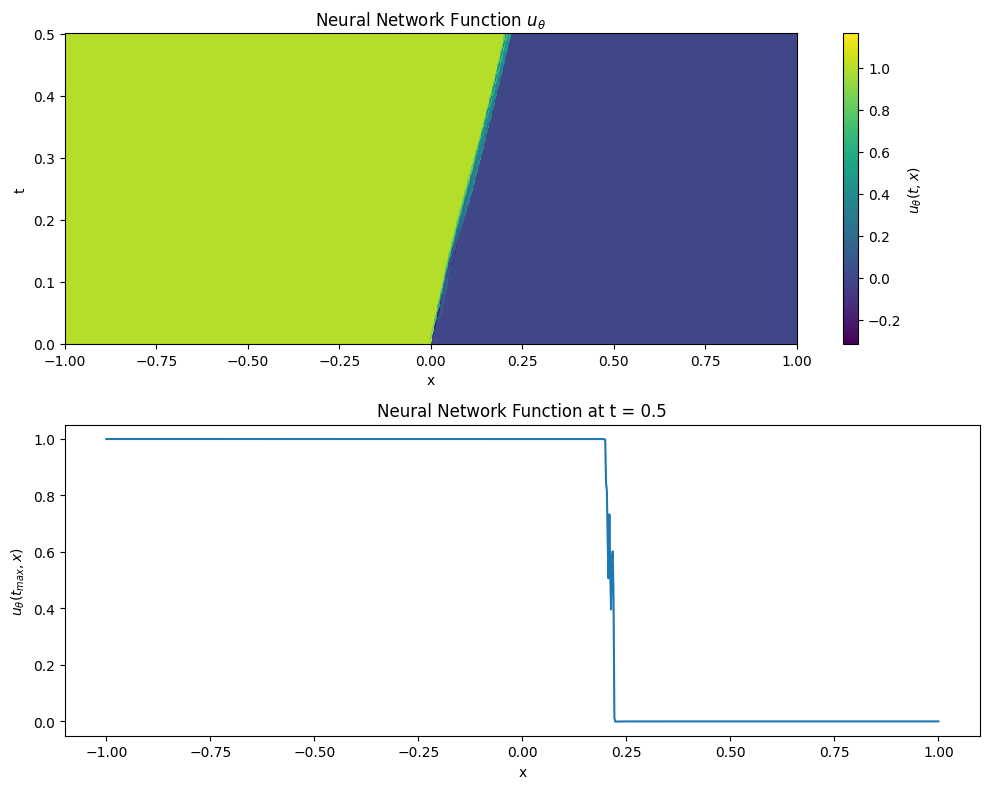

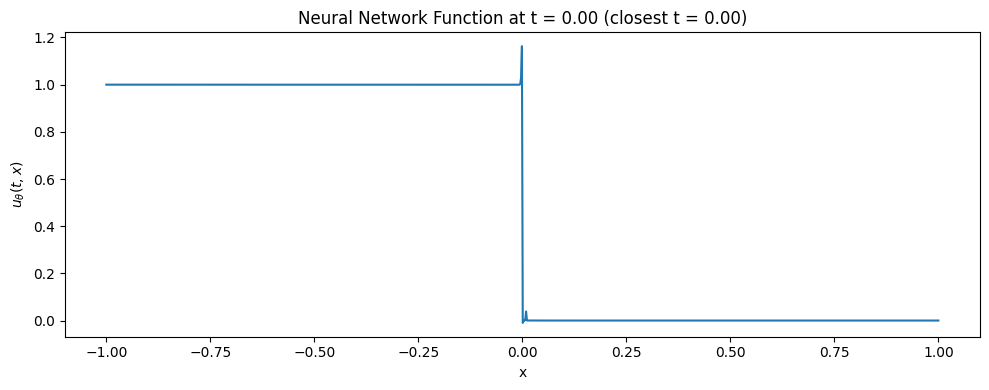

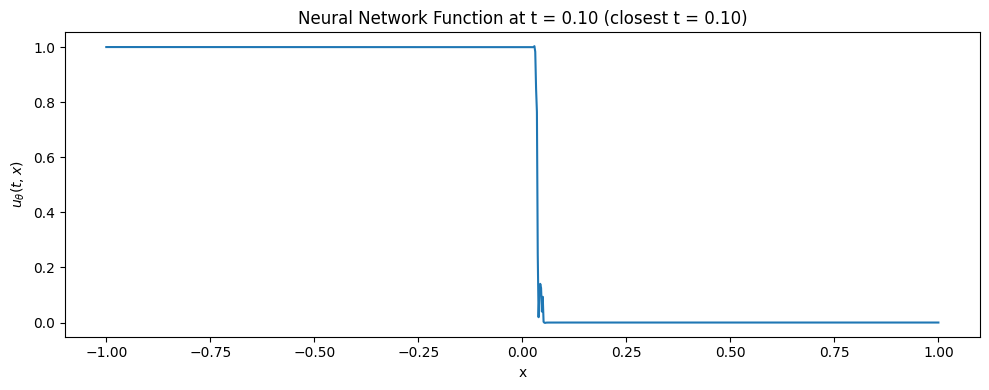

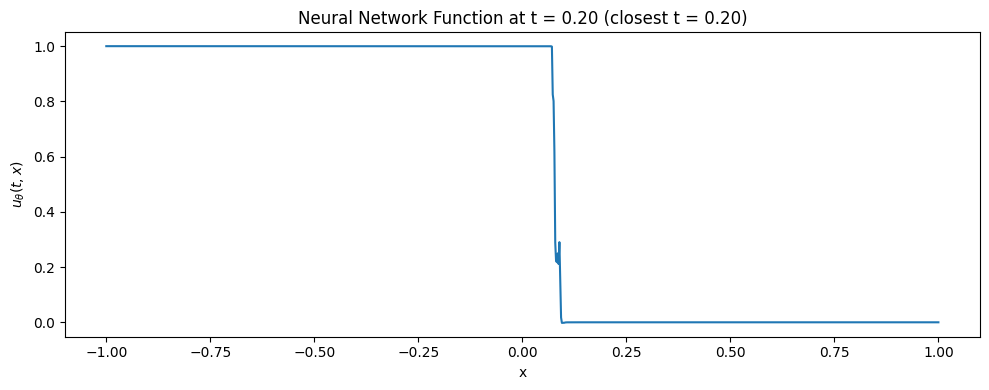

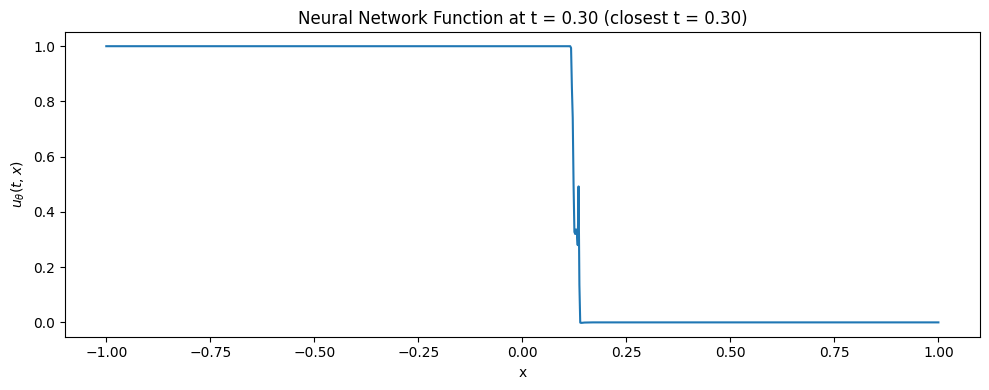

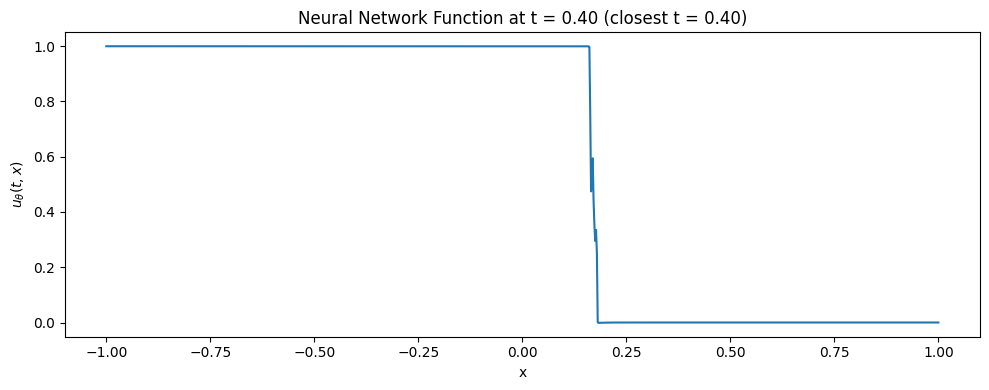

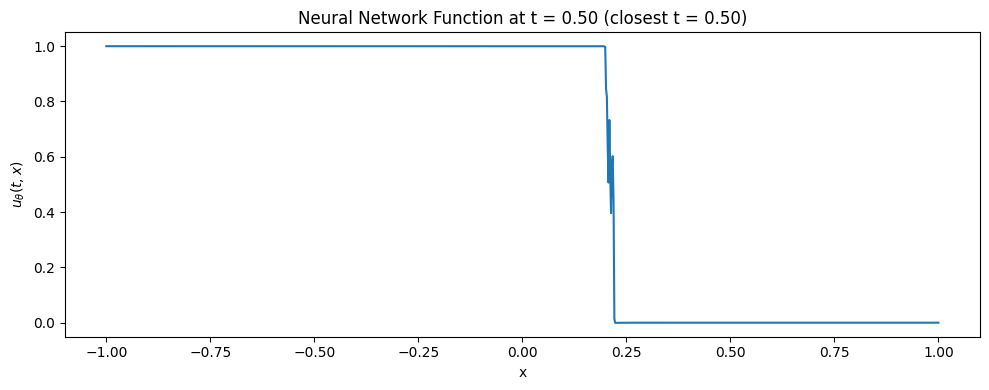

In [5]:
# optProb.train_process_stage2()
from my_helpers import plot_u_theta
plot_u_theta(optProb.model, M_t=500, M_x=1000, t_min=0.0, t_max=0.5, x_min=-1.0, x_max=1.0, ts=[0.1*i for i in range(6)])  # Plot initial model state


In [34]:
compute_errors(optProb.model, file_path='data/burgers_sin_ref.npz')

Relative error at T: 0.013388077580121584
Space-time relative error: 0.011679391725314864


(np.float64(0.013388077580121584), np.float64(0.011679391725314864))

In [26]:
pwd

'/Users/haoli/Desktop/Conservation_law/NN-HCL/Code'

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


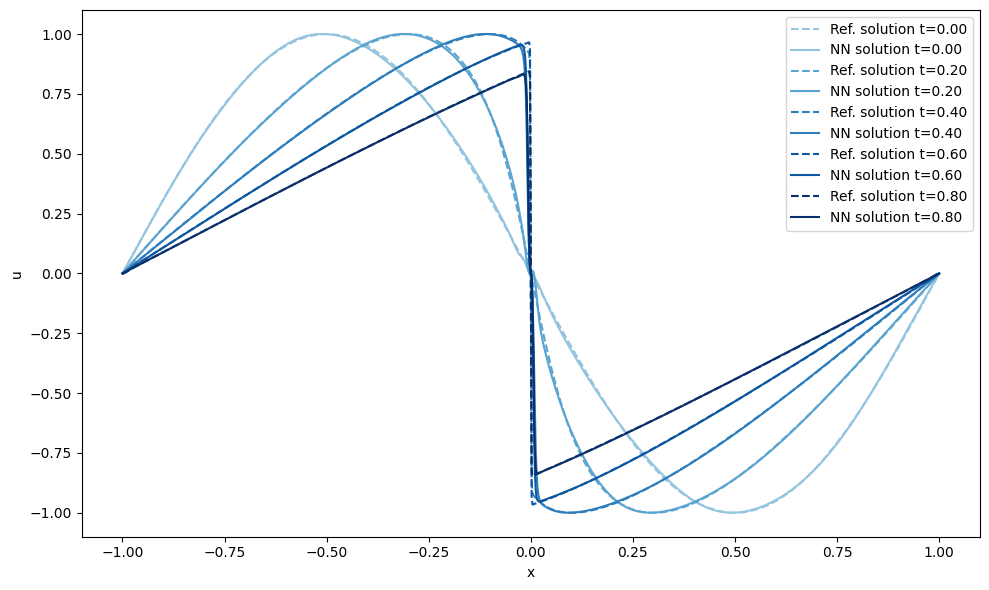

In [31]:
ts = [i*0.2 for i in range(5)]
plot_comparison_together(optProb.model, file_path='data/burgers_sin_ref.npz', ts=ts)

In [33]:
def plot_numerical_solution(file_path='data/burgers_sin_ref.npz', ts=None):
    """
    Plot the numerical solution u over the time and space domain from the saved .npz file,
    including a 2D color mesh plot and a 1D plot at the maximum time. Additionally, plot
    separate 1D snapshots for each timestamp in ts if provided.

    Args:
        file_path: Path to the .npz file containing 'times', 'x', and 'u' (default: 'data/burgers_sin_ref.npz').
        ts: List or array of timestamps for which to plot individual 1D snapshots (default: None).
    """
    if ts is None:
        ts = []

    # Load the data from the .npz file
    data = np.load(file_path)
    times = data['times']
    x = data['x']
    u = data['u']  # Shape: (n_times, n_x)

    # Create figure with two subplots for the main plot
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 8))

    # 2D color mesh plot
    pcm = ax1.pcolormesh(x, times, u, shading='nearest', cmap='viridis')
    fig.colorbar(pcm, ax=ax1, label='$u(t, x)$')
    ax1.set_xlabel('x')
    ax1.set_ylabel('t')
    ax1.set_title('Numerical Solution $u$')

    # 1D plot at t = max(times)
    ax2.plot(x, u[-1, :])
    ax2.set_xlabel('x')
    ax2.set_ylabel('$u(t_{max}, x)$')
    ax2.set_title(f'Numerical Solution at t = {times[-1]:.2f}')

    # Adjust layout and display the main plot
    plt.tight_layout()
    plt.show()

    # Plot separate figures for each timestamp in ts
    for t_val in ts:
        # Find the closest index in times
        idx = np.argmin(np.abs(times - t_val))
        # Create a new figure for the snapshot
        fig, ax = plt.subplots(1, 1, figsize=(10, 4))
        ax.plot(x, u[idx, :])
        ax.set_xlabel('x')
        ax.set_ylabel('$u(t, x)$')
        ax.set_title(f'Numerical Solution at t = {t_val:.2f} (closest t = {times[idx]:.2f})')
        plt.tight_layout()
        plt.show()


def compute_errors(model, file_path='data/burgers_sin_ref.npz', params=None, T=None):
    """
    Compute the relative error at time T and the space-time relative error between
    the neural network approximation u* and the numerical solution u.

    Args:
        model: Flax model instance representing u_theta.
        file_path: Path to the .npz file containing 'times', 'x', and 'u' (default: 'data/burgers_sin_ref.npz').
        params: Parameters (pytree) of the neural network (default: None).
        T: The final time for the error at T. If None, uses the maximum time in the data (default: None).

    Returns:
        err_T: Relative error at time T.
        err_spacetime: Space-time relative error.
    """
    # Load the numerical solution data
    data = np.load(file_path)
    times = data['times']
    x = data['x']
    u_num = data['u']  # Shape: (n_times, n_x)

    if T is None:
        T = times[-1]

    # Create grid for evaluation (matching the numerical grid)
    t_grid, x_grid = np.meshgrid(times, x, indexing='ij')  # Shapes: (n_t, n_x)
    tx_points = np.stack([t_grid.ravel(), x_grid.ravel()], axis=1)  # Shape: (n_t * n_x, 2)

    # Evaluate the neural network on the grid points
    if params is None:
        u_star_values = model.forward(tx_points)
    else:
        u_star_values = model(params, tx_points)  # Assuming shape: (n_points, 1) or (n_points,)
    u_star_values = np.asarray(u_star_values).squeeze()  # Ensure it's 1D array
    u_star = u_star_values.reshape(len(times), len(x))  # Shape: (n_t, n_x)

    # Compute relative error at t = T
    idx_T = np.argmin(np.abs(times - T))
    u_T = u_num[idx_T, :]
    u_star_T = u_star[idx_T, :]
    num_T = np.trapezoid(np.abs(u_star_T - u_T), x)
    den_T = np.trapezoid(np.abs(u_T), x)
    err_T = num_T / den_T if den_T != 0 else np.inf

    # Compute space-time relative error
    abs_diff = np.abs(u_star - u_num)  # Shape: (n_t, n_x)
    abs_u = np.abs(u_num)

    # Integrate over x for each t
    int_x_abs_diff = np.trapezoid(abs_diff, x, axis=1)  # Shape: (n_t,)
    int_x_abs_u = np.trapezoid(abs_u, x, axis=1)

    # Integrate over t
    spacetime_num = np.trapezoid(int_x_abs_diff, times)
    spacetime_den = np.trapezoid(int_x_abs_u, times)
    err_spacetime = spacetime_num / spacetime_den if spacetime_den != 0 else np.inf

    # Print the errors
    print(f"Relative error at T: {err_T}")
    print(f"Space-time relative error: {err_spacetime}")

    return err_T, err_spacetime


def plot_comparison_seperate(model, params=None, file_path='data/burgers_sin_ref.npz', ts=None):
    """
    Plot both the neural network solution and the numerical solution for each timestamp in ts,
    with both solutions overlaid on the same axes in subplots (one subplot per timestamp).

    Args:
        model: Flax model instance representing u_theta.
        params: Parameters (pytree) of the neural network (default: None).
        file_path: Path to the .npz file containing 'times', 'x', and 'u' (default: '/data/burgers_sin_ref.npz').
        ts: List or array of timestamps for which to plot the solutions (default: None).
    """
    if ts is None:
        ts = []
    if not ts:
        print("No timestamps provided. Nothing to plot.")
        return

    # Load the numerical solution data
    data = np.load(file_path)
    times = data['times']
    x = data['x']
    u_num = data['u']  # Shape: (n_times, n_x)

    # Create subplots: one for each timestamp
    fig, axs = plt.subplots(len(ts), 1, figsize=(10, 4 * len(ts)), squeeze=False)
    axs = axs.flatten()  # Ensure axs is iterable even for len(ts)=1

    for i, t_val in enumerate(ts):
        # Numerical solution: find closest time index
        idx = np.argmin(np.abs(times - t_val))
        u_num_t = u_num[idx, :]

        # Neural network solution: evaluate at exact t_val on the same x grid
        x_jnp = jnp.asarray(x)
        t_jnp = jnp.full_like(x_jnp, t_val)
        tx_points = jnp.stack([t_jnp, x_jnp], axis=1)  # Shape: (n_x, 2)

        if params is None:
            u_nn_values = model.forward(tx_points)
        else:
            u_nn_values = model(params, tx_points)
        u_nn_t = np.asarray(u_nn_values).squeeze()  # Shape: (n_x,)

        # Plot both on the same axes
        ax = axs[i]
        ax.plot(x, u_num_t, label='Numerical', linewidth=2)
        ax.plot(x, u_nn_t, label='Neural Network', linestyle='--', linewidth=2)
        ax.legend()
        ax.set_xlabel('x')
        ax.set_ylabel('u')
        ax.set_title(f'Solutions at t = {t_val:.2f} (numerical closest t = {times[idx]:.2f})')

    plt.tight_layout()
    plt.show()


In [30]:
def plot_comparison_together(model, params=None, file_path='data/burgers_sin_ref.npz', ts=None, save_path='data/sine_wave_plot_together.eps', title=None):
    """
    Plot both the neural network solution (solid line) and the numerical solution (dashed line)
    for each timestamp in ts, with all comparisons overlaid on the same single figure. For each
    time, the pair of lines (numerical and neural) share the same color, progressing from light
    to dark as time increases.

    Args:
        model: Flax model instance representing u_theta.
        params: Parameters (pytree) of the neural network (default: None).
        file_path: Path to the .npz file containing 'times', 'x', and 'u' (default: '/burgers_sin_ref.npz').
        ts: List or array of timestamps for which to plot the solutions (default: None).
    """
    if ts is None:
        ts = []
    if not ts:
        print("No timestamps provided. Nothing to plot.")
        return

    # Load the numerical solution data
    data = np.load(file_path)
    times = data['times']
    x = data['x']
    u_num = data['u']  # Shape: (n_times, n_x)

    # Create a single figure and axes
    fig, ax = plt.subplots(figsize=(10, 6))

    # Get colormap (light to dark blue)
    cmap = plt.cm.Blues

    # Normalize times for color mapping
    ts_array = np.array(ts)
    min_t = ts_array.min()
    max_t = ts_array.max()
    if min_t == max_t:
        norms = np.full(len(ts), 0.5)  # Medium color if all times are the same
    else:
        norms = 0.6*(ts_array - min_t) / (max_t - min_t) + 0.4

    for i, t_val in enumerate(ts):
        norm = norms[i]
        color = cmap(norm)

        # Numerical solution: find closest time index
        idx = np.argmin(np.abs(times - t_val))
        u_num_t = u_num[idx, :]

        # Neural network solution: evaluate at exact t_val on the same x grid
        x_jnp = jnp.asarray(x)
        t_jnp = jnp.full_like(x_jnp, t_val)
        tx_points = jnp.stack([t_jnp, x_jnp], axis=1)  # Shape: (n_x, 2)

        if params is None:
            u_nn_values = model.forward(tx_points)
        else:
            u_nn_values = model(params, tx_points)
        u_nn_t = np.asarray(u_nn_values).squeeze()  # Shape: (n_x,)

        # Plot both on the same axes with same color
        ax.plot(x, u_num_t, linestyle='--', color=color, label=f'Ref. solution t={t_val:.2f}')
        ax.plot(x, u_nn_t, linestyle='-', color=color, label=f'NN solution t={t_val:.2f}')

    ax.legend()
    ax.set_xlabel('x')
    ax.set_ylabel('u')
    if title is not None:
        ax.set_title(title)

    plt.tight_layout()
    plt.savefig(save_path, format='eps', bbox_inches='tight')
    plt.show()


In [3]:
print(os.environ.get('ENABLE_PJRT_COMPATIBILITY'))

1
